# [선택 과제] fastText 사전학습 단어 벡터로 임베딩 초기화

5단계 과제 안내의 선택 항목이다: *"fasttext로 사전훈련된 Word Vector를 사용할 수 있지만 … 기본적인 태스크를 끝나고 도전하시는걸 추천합니다."*

**질문:** 임베딩을 무작위로 시작하는 대신 fastText 한국어 사전학습 벡터(`cc.ko.300`, Common Crawl + Wikipedia)로 시작하면 성능이 오를까? SentencePiece와 MeCab 중 어느 쪽이 더 덕을 볼까?

**조건은 v2(`02_Sentiment_Analysis.ipynb`)와 똑같이 맞췄다:** NSMC 전체, 검증 10% 분리(`random_state=42`), MAX_LEN 60, BiLSTM(은닉 128), 10에폭 중 최고 검증 에폭으로 테스트 1회, 시드 5개. 토크나이저는 v2의 형태소 최고 **MeCab-8000**과 SentencePiece 최고 **SPM-unigram-16000**이다(둘 다 검증 기준).

| 임베딩 설정 | 차원 | 초기값 | 학습 중 |
|---|---|---|---|
| `random-128` | 128 | 무작위 | 학습 (v2와 같은 설정, 재현 확인용) |
| `random-300` | 300 | 무작위 | 학습 (차원만 키운 대조군) |
| `fasttext-300` | 300 | fastText | 학습 (미세조정) |
| `fasttext-300-frozen` | 300 | fastText | 고정 |

`random-300`을 둔 이유: fastText는 300차원이라, 그냥 비교하면 "사전학습 덕분"인지 "차원이 커져서"인지 구분할 수 없다.

**Colab 사용법:** 런타임 유형을 GPU(A100 권장) + 고용량 RAM으로 바꾸고 **모두 실행**. fastText 벡터 파일이 약 7GB라 내려받고 불러오는 데 몇 분 걸린다.

## 설치 (konlpy, sentencepiece, MeCab, fasttext)

In [7]:
!pip install -q konlpy sentencepiece
%cd /content
!test -d Mecab-ko-for-Google-Colab || git clone -q https://github.com/SOMJANG/Mecab-ko-for-Google-Colab.git
%cd /content/Mecab-ko-for-Google-Colab
!bash install_mecab-ko_on_colab_light_220429.sh > /tmp/mecab_install.log 2>&1; tail -n 3 /tmp/mecab_install.log
%cd /content
!pip install -q fasttext || pip install -q fasttext-wheel

/content
/content/Mecab-ko-for-Google-Colab
블로그에 해결 방법을 남겨주신 tana님 감사합니다.
light 버전 작성 : Dogdriip님 ( https://github.com/Dogdriip )
문제를 해결해주신 combacsa님 감사합니다.
/content


## 데이터와 토크나이저 (v2와 같은 절차)

In [8]:
import os, random, copy, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pad_sequence
import sentencepiece as spm
from konlpy.tag import Mecab

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device, torch.cuda.get_device_name(0) if device == 'cuda' else '')

SEEDS = [0, 1, 2, 3, 4]
EPOCHS = 10
MAX_LEN = 60
BATCH = 256

!wget -q -nc https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt
!wget -q -nc https://raw.githubusercontent.com/e9t/nsmc/master/ratings_test.txt

def load(path):
    df = pd.read_table(path).dropna().drop_duplicates(subset=['document'])
    df['document'] = df['document'].str.replace('\n', ' ')
    return df[df['document'].str.strip() != ''].reset_index(drop=True)

train_all = load('ratings_train.txt')
test_df = load('ratings_test.txt')
val_df = train_all.groupby('label', group_keys=False).sample(frac=0.1, random_state=42)
train_df = train_all.drop(val_df.index)
texts = {'train': train_df['document'].tolist(), 'val': val_df['document'].tolist(), 'test': test_df['document'].tolist()}
labels = {'train': train_df['label'].values, 'val': val_df['label'].values, 'test': test_df['label'].values}
for k in texts:
    print(f'{k:5s} {len(texts[k]):7,d}개  긍정 비율 {labels[k].mean():.3f}')

cuda NVIDIA A100-SXM4-40GB
train 131,564개  긍정 비율 0.498
val    14,618개  긍정 비율 0.498
test   49,157개  긍정 비율 0.503


In [9]:
def sp_tokenize(s, corpus, vocab_path='./korean_spm.vocab', max_len=None):
    tensor = []
    for sen in corpus:
        ids = s.EncodeAsIds(sen)
        if max_len:
            ids = ids[:max_len]
        # 📄 원본: tensor.append(s.EncodeAsIds(sen))
        # 🔧 수정: list → tensor (pad_sequence는 tensor만 받는다)
        tensor.append(torch.tensor(ids, dtype=torch.long))

    with open(vocab_path, 'r', encoding='utf-8') as f:
        vocab = f.readlines()

    word_index = {}
    index_word = {}
    for idx, line in enumerate(vocab):
        word = line.split('\t')[0]
        word_index.update({word: idx})
        index_word.update({idx: word})

    tensor = pad_sequence(tensor, batch_first=True, padding_value=0)
    return tensor, word_index, index_word

def to_tensor(id_lists, max_len):
    seqs = [torch.tensor(ids[:max_len] or [1], dtype=torch.long) for ids in id_lists]
    return pad_sequence(seqs, batch_first=True, padding_value=0)

TOK = {}

# SentencePiece unigram 16000 (v2와 같은 입력·옵션)
with open('nsmc_train_v2.txt', 'w', encoding='utf-8') as f:
    for t in texts['train']:
        f.write(t + '\n')
prefix = 'nsmc_v2_unigram_16000'
spm.SentencePieceTrainer.Train(
    f'--input=nsmc_train_v2.txt --model_prefix={prefix} --vocab_size=16000 '
    f'--model_type=unigram --pad_id=0 --unk_id=1 --bos_id=2 --eos_id=3 --minloglevel=2'
)
sp = spm.SentencePieceProcessor()
sp.Load(f'{prefix}.model')
X = {}
for k, v in texts.items():
    X[k], sp_word_index, sp_index_word = sp_tokenize(sp, v, f'{prefix}.vocab', MAX_LEN)
TOK['SPM-unigram-16000'] = dict(X=X, index_word=sp_index_word, n_special=4)

# MeCab 8000 (v2와 같은 방식: 학습 데이터 빈도순, 0=pad, 1=unk)
mecab = Mecab()
t0 = time.time()
morphs = {k: [mecab.morphs(t) for t in v] for k, v in texts.items()}
print(f'MeCab 형태소 분석 {time.time() - t0:.0f}초')
cnt = Counter(w for ts in morphs['train'] for w in ts)
mecab_word_index = {w: i + 2 for i, (w, _) in enumerate(cnt.most_common(8000 - 2))}
mecab_index_word = {0: '<pad>', 1: '<unk>', **{i: w for w, i in mecab_word_index.items()}}
ids = {k: [[mecab_word_index.get(w, 1) for w in ts] for ts in v] for k, v in morphs.items()}
TOK['MeCab-8000'] = dict(X={k: to_tensor(v, MAX_LEN) for k, v in ids.items()}, index_word=mecab_index_word, n_special=2)

for name, t in TOK.items():
    print(name, 'vocab', len(t['index_word']), {k: tuple(v.shape) for k, v in t['X'].items()})

MeCab 형태소 분석 12초
SPM-unigram-16000 vocab 16000 {'train': (131564, 60), 'val': (14618, 60), 'test': (49157, 60)}
MeCab-8000 vocab 8000 {'train': (131564, 60), 'val': (14618, 60), 'test': (49157, 60)}


## fastText 한국어 벡터 불러오기

`cc.ko.300.bin`은 단어 벡터와 함께 글자 n-gram 벡터를 갖고 있어서, 사전에 없는 토큰도 글자 조각을 합쳐 벡터를 만들 수 있다. SentencePiece 조각의 `▁`(단어 시작 표시)는 떼고 조회한다.

In [10]:
if not os.path.exists('cc.ko.300.bin'):
    !wget -q https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.ko.300.bin.gz
    !gunzip -f cc.ko.300.bin.gz
!ls -lh cc.ko.300.bin

import fasttext
t0 = time.time()
ft = fasttext.load_model('cc.ko.300.bin')
print(f'불러오기 {time.time() - t0:.0f}초, 차원 {ft.get_dimension()}, 단어 수 {len(ft.get_words(on_unicode_error="replace")):,}')

-rw-r--r-- 1 root root 6.8G Jan 18  2019 cc.ko.300.bin
불러오기 6초, 차원 300, 단어 수 2,000,000


In [6]:
def build_embedding(index_word, n_special, dim=300, seed=0):
    rng = np.random.default_rng(seed)
    W = np.zeros((len(index_word), dim), dtype=np.float32)
    in_vocab, subword, empty = 0, 0, 0
    for idx in range(len(index_word)):
        if idx == 0:
            continue                                  # <pad>는 0 벡터
        if idx < n_special:
            W[idx] = rng.normal(0, 0.1, dim)          # <unk>, <s>, </s>
            continue
        word = index_word[idx].replace('▁', '')
        if not word:
            W[idx] = rng.normal(0, 0.1, dim)          # '▁' 하나만 있는 조각
            empty += 1
            continue
        W[idx] = ft.get_word_vector(word)
        if ft.get_word_id(word) != -1:
            in_vocab += 1
        else:
            subword += 1
    n = len(index_word) - n_special
    stats = dict(fastText_사전에_있음=in_vocab / n, 글자조각으로_생성=subword / n, 빈_조각=empty / n)
    return torch.tensor(W), stats

EMB, cover = {}, {}
for name, t in TOK.items():
    EMB[name], cover[name] = build_embedding(t['index_word'], t['n_special'])
display(pd.DataFrame(cover).T.round(4))

for name, t in TOK.items():
    words = [t['index_word'][i] for i in range(t['n_special'], t['n_special'] + 12)]
    print(name, '자주 나오는 토큰:', words)
for w in ['재밌', '최고', '노잼', '평점']:
    print(w, '→', [x for _, x in ft.get_nearest_neighbors(w, k=5)])

,fastText_사전에_있음,글자조각으로_생성,빈_조각
SPM-unigram-16000,0.9169,0.0831,0.0001
MeCab-8000,0.9386,0.0614,0.0000


SPM-unigram-16000 자주 나오는 토큰: ['.', '▁', '..', '▁영화', '...', '이', '의', ',', '도', '가', '는', '을']
MeCab-8000 자주 나오는 토큰: ['.', '이', '는', '영화', '다', '고', '하', '도', '의', '가', '은', '에']
재밌 → ['변했', '놀랍', '빛났', '젖혔', '어렸']
최고 → ['最古', '최강에', '最高', '공항상', '권위인']
노잼 → ['꿀잼', '웃김', '열폭', 'ㄹㅇ', '노답']
평점 → ['0.0점', '2.5점', '4.0점', '구매수', '4.3점']


## 학습 함수

v2와 같은 BiLSTM 분류기다. 바뀐 점은 임베딩 차원과 초기값을 고를 수 있다는 것 하나다.

In [11]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim=128, hidden=128, pretrained=None, freeze=False):
        super().__init__()
        if pretrained is None:
            self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        else:
            self.emb = nn.Embedding.from_pretrained(pretrained, freeze=freeze, padding_idx=0)
            emb_dim = pretrained.shape[1]
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden * 2, 1)

    def forward(self, x):
        out, _ = self.lstm(self.emb(x))
        mask = (x != 0).unsqueeze(-1).float()
        pooled = (out * mask).sum(1) / mask.sum(1).clamp(min=1)
        return self.fc(pooled).squeeze(-1)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

@torch.no_grad()
def predict(model, X, bs=4096):
    model.eval()
    return torch.cat([(model(X[i:i + bs]) > 0).long().cpu() for i in range(0, len(X), bs)]).numpy()

def run(X, y, make_model, seed, epochs=EPOCHS, bs=BATCH):
    set_seed(seed)
    Xtr, Xva, Xte = X['train'].to(device), X['val'].to(device), X['test'].to(device)
    ytr = torch.tensor(y['train'], dtype=torch.float, device=device)
    model = make_model().to(device)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=1e-3)
    loss_fn = nn.BCEWithLogitsLoss()
    g = torch.Generator().manual_seed(seed)
    hist, best_acc, best_state, best_ep = [], -1, None, 0
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(Xtr), generator=g).to(device)
        total = 0.0
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            opt.zero_grad()
            loss = loss_fn(model(Xtr[idx]), ytr[idx])
            loss.backward()
            opt.step()
            total += loss.item() * len(idx)
        va_acc = (predict(model, Xva) == y['val']).mean()
        hist.append(dict(epoch=ep, train_loss=total / len(Xtr), val_acc=va_acc))
        if va_acc > best_acc:
            best_acc, best_state, best_ep = va_acc, copy.deepcopy(model.state_dict()), ep
    model.load_state_dict(best_state)
    te_pred = predict(model, Xte)
    return dict(seed=seed, best_ep=best_ep, val_acc=best_acc, test_acc=(te_pred == y['test']).mean(), hist=hist)

## 실행 (토크나이저 2개 × 임베딩 설정 4개 × 시드 5개 = 40회)

In [12]:
SETTINGS = {
    'random-128':          lambda V, E: (lambda: LSTMClassifier(V, emb_dim=128)),
    'random-300':          lambda V, E: (lambda: LSTMClassifier(V, emb_dim=300)),
    'fasttext-300':        lambda V, E: (lambda: LSTMClassifier(V, pretrained=E.clone(), freeze=False)),
    'fasttext-300-frozen': lambda V, E: (lambda: LSTMClassifier(V, pretrained=E.clone(), freeze=True)),
}
RESULTS = []
t_all = time.time()
for name, t in TOK.items():
    V = len(t['index_word'])
    for setting, factory in SETTINGS.items():
        for seed in SEEDS:
            t0 = time.time()
            r = run(t['X'], labels, factory(V, EMB[name]), seed)
            r.update(tokenizer=name, setting=setting)
            RESULTS.append(r)
            print(f"{name:18s} {setting:20s} seed {seed}  best_ep {r['best_ep']:2d}  val {r['val_acc']:.4f}  test {r['test_acc']:.4f}  ({time.time() - t0:.0f}s)")
print(f'전체 {(time.time() - t_all) / 60:.1f}분')

with open('results_fasttext.json', 'w') as f:
    json.dump(RESULTS, f, default=float)

SPM-unigram-16000  random-128           seed 0  best_ep  4  val 0.8509  test 0.8458  (27s)
SPM-unigram-16000  random-128           seed 1  best_ep  4  val 0.8508  test 0.8462  (19s)
SPM-unigram-16000  random-128           seed 2  best_ep  3  val 0.8519  test 0.8474  (19s)
SPM-unigram-16000  random-128           seed 3  best_ep  4  val 0.8521  test 0.8490  (19s)
SPM-unigram-16000  random-128           seed 4  best_ep  4  val 0.8518  test 0.8462  (19s)
SPM-unigram-16000  random-300           seed 0  best_ep  2  val 0.8505  test 0.8487  (21s)
SPM-unigram-16000  random-300           seed 1  best_ep  4  val 0.8488  test 0.8448  (21s)
SPM-unigram-16000  random-300           seed 2  best_ep  3  val 0.8565  test 0.8485  (21s)
SPM-unigram-16000  random-300           seed 3  best_ep  3  val 0.8512  test 0.8507  (21s)
SPM-unigram-16000  random-300           seed 4  best_ep  2  val 0.8526  test 0.8473  (21s)
SPM-unigram-16000  fasttext-300         seed 0  best_ep  2  val 0.8646  test 0.8615  (21s)

## 결과 요약 (시드 5개 평균 ± 표준편차)

In [13]:
df = pd.DataFrame([{k: v for k, v in r.items() if k != 'hist'} for r in RESULTS])
summary = (df.groupby(['tokenizer', 'setting'])
             .agg(val_mean=('val_acc', 'mean'), val_std=('val_acc', 'std'),
                  test_mean=('test_acc', 'mean'), test_std=('test_acc', 'std'),
                  best_ep=('best_ep', 'mean'))
             .reindex(list(SETTINGS), level='setting'))
display(summary.round(4))

print('v2 기록 (random-128, 테스트): MeCab-8000 0.8620 ± 0.0022 / SPM-unigram-16000 0.8469 ± 0.0013')
for name in TOK:
    base = df[(df.tokenizer == name) & (df.setting == 'random-300')].set_index('seed')['test_acc']
    for setting in ['fasttext-300', 'fasttext-300-frozen']:
        d = df[(df.tokenizer == name) & (df.setting == setting)].set_index('seed')['test_acc'] - base
        print(f'{name:18s} {setting:20s} - random-300 (같은 시드, 테스트): {d.mean() * 100:+.2f}%p ± {d.std() * 100:.2f}%p, 시드별 {list((d * 100).round(2))}')

val_mean  val_std  test_mean  test_std  \
tokenizer         setting                                                       
MeCab-8000        random-128             0.8647   0.0017     0.8620    0.0022   
                  random-300             0.8649   0.0022     0.8645    0.0009   
                  fasttext-300           0.8646   0.0012     0.8638    0.0004   
                  fasttext-300-frozen    0.8600   0.0012     0.8590    0.0012   
SPM-unigram-16000 random-128             0.8515   0.0006     0.8469    0.0013   
                  random-300             0.8519   0.0029     0.8480    0.0022   
                  fasttext-300           0.8654   0.0006     0.8616    0.0007   
                  fasttext-300-frozen    0.8479   0.0021     0.8425    0.0014   

                                       best_ep  
tokenizer         setting                       
MeCab-8000        random-128               4.2  
                  random-300               3.4  
                  fasttext-300             3.4  
                  fasttext-300-frozen      8.6  
SPM-unigram-16000 random-128               3.8  
                  random-300               2.8  
                  fasttext-300             2.0  
                  fasttext-300-frozen      8.0

v2 기록 (random-128, 테스트): MeCab-8000 0.8620 ± 0.0022 / SPM-unigram-16000 0.8469 ± 0.0013
SPM-unigram-16000  fasttext-300         - random-300 (같은 시드, 테스트): +1.36%p ± 0.27%p, 시드별 [1.28, 1.76, 1.23, 1.06, 1.5]
SPM-unigram-16000  fasttext-300-frozen  - random-300 (같은 시드, 테스트): -0.55%p ± 0.24%p, 시드별 [-0.74, -0.18, -0.43, -0.75, -0.63]
MeCab-8000         fasttext-300         - random-300 (같은 시드, 테스트): -0.07%p ± 0.07%p, 시드별 [0.04, -0.13, -0.12, -0.1, -0.03]
MeCab-8000         fasttext-300-frozen  - random-300 (같은 시드, 테스트): -0.54%p ± 0.14%p, 시드별 [-0.52, -0.66, -0.4, -0.7, -0.43]


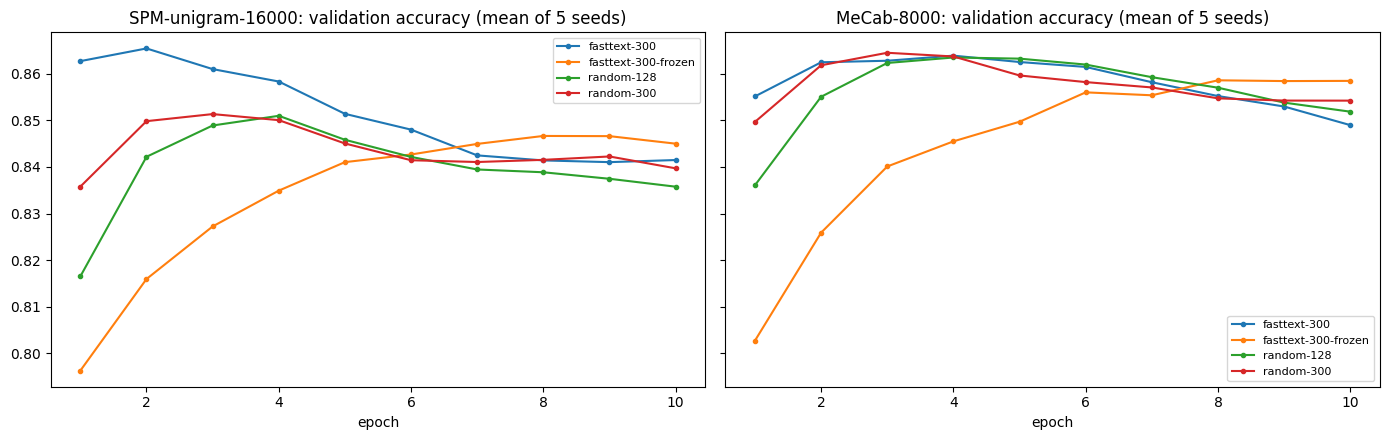

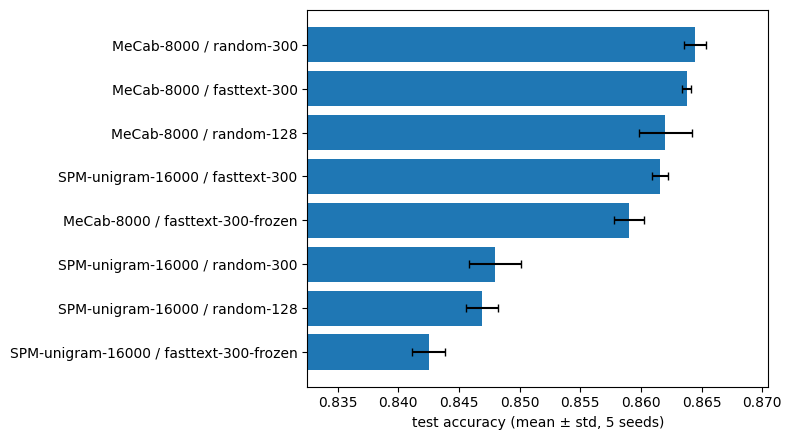

In [14]:
hist = pd.DataFrame([dict(h, tokenizer=r['tokenizer'], setting=r['setting'], seed=r['seed']) for r in RESULTS for h in r['hist']])
curve = hist.groupby(['tokenizer', 'setting', 'epoch'])[['train_loss', 'val_acc']].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, name in zip(axes, TOK):
    for setting, g in curve[curve.tokenizer == name].groupby('setting'):
        ax.plot(g['epoch'], g['val_acc'], marker='o', ms=3, label=setting)
    ax.set_title(f'{name}: validation accuracy (mean of 5 seeds)')
    ax.set_xlabel('epoch')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

order = summary['test_mean'].sort_values().index
plt.figure(figsize=(8, 4.5))
plt.barh([f'{a} / {b}' for a, b in order], summary.loc[order, 'test_mean'], xerr=summary.loc[order, 'test_std'], capsize=3)
plt.xlim(summary['test_mean'].min() - 0.01, summary['test_mean'].max() + 0.006)
plt.xlabel('test accuracy (mean ± std, 5 seeds)')
plt.tight_layout()
plt.show()

## 결과 해석

| 토크나이저 | 임베딩 | 검증 | 테스트 | 최고 에폭 |
|---|---|---|---|---|
| MeCab-8000 | random-128 (v2 설정) | 0.8647 ± 0.0017 | 0.8620 ± 0.0022 | 4.2 |
| MeCab-8000 | random-300 | 0.8649 ± 0.0022 | **0.8645 ± 0.0009** | 3.4 |
| MeCab-8000 | fasttext-300 | 0.8646 ± 0.0012 | 0.8638 ± 0.0004 | 3.4 |
| MeCab-8000 | fasttext-300-frozen | 0.8600 ± 0.0012 | 0.8590 ± 0.0012 | 8.6 |
| SPM-unigram-16000 | random-128 (v2 설정) | 0.8515 ± 0.0006 | 0.8469 ± 0.0013 | 3.8 |
| SPM-unigram-16000 | random-300 | 0.8519 ± 0.0029 | 0.8480 ± 0.0022 | 2.8 |
| SPM-unigram-16000 | **fasttext-300** | **0.8654 ± 0.0006** | 0.8616 ± 0.0007 | 2.0 |
| SPM-unigram-16000 | fasttext-300-frozen | 0.8479 ± 0.0021 | 0.8425 ± 0.0014 | 8.0 |

- **재현 확인**: `random-128`은 v2와 시드별 숫자까지 똑같이 나왔다. 같은 조건에서 비교한 결과라고 볼 수 있다.
- **SentencePiece는 fastText 덕을 크게 봤다.** 같은 300차원 무작위 대비 같은 시드끼리 테스트 **+1.36%p ± 0.27%p**였고, 시드 5개 모두 올랐다(1.06~1.76%p). 검증 0.8654로 8개 설정 중 가장 높았다. 1에폭부터 검증 0.863으로 출발해 2에폭에 최고가 됐다.
- **MeCab은 거의 변화가 없었다**(-0.07%p ± 0.07%p).
- **그래서 v2 결론이 달라진다.** 무작위 임베딩에서는 MeCab이 1.5%p 앞섰지만, fastText로 시작하면 SPM-unigram-16000(테스트 0.8616)이 v2의 MeCab-8000(0.8620)과 거의 같아진다. 검증으로 고르면 SPM+fastText(0.8654)와 MeCab random-300(0.8649)이 0.05%p 차이라 사실상 동률이다. 테스트로 보면 MeCab random-300이 0.29%p 높다.
- **벡터를 고정하면 손해다.** 두 토크나이저 모두 -0.5%p 정도 떨어졌다(SPM -0.55%p ± 0.24%p, MeCab -0.54%p ± 0.14%p). 검증 정확도가 8~9에폭까지 천천히 오르다 멈춘다. 이웃 단어를 보면 `노잼`과 가장 가까운 단어가 `꿀잼`이었다. fastText는 비슷한 문맥에 나오는 단어를 가깝게 두기 때문에, 반대 감정의 단어도 붙어 있다. 감정 분류에 맞게 벡터를 다시 학습(미세조정)해야 하는 이유로 보인다.
- **차원만 키운 효과는 작다.** `random-128` → `random-300`은 테스트 +0.11~0.25%p였다. SentencePiece의 +1.4%p는 차원이 아니라 사전학습 덕분이다.
- **fastText 사전 포함률은 둘 다 높았다**(SPM 91.7%, MeCab 93.9%). 그래서 포함률 차이로는 효과 차이를 설명할 수 없다.

**왜 SentencePiece만 덕을 봤나 (추측, 확인하지 않음):** fastText `cc.ko`는 공백으로 나뉜 웹 문서로 학습했다. 그래서 `▁영화가`처럼 어절에 가까운 SentencePiece 조각에는 쓸 만한 벡터가 있었을 것이다. 반면 MeCab의 `이`, `는`, `하` 같은 짧은 형태소는 웹 문서에서 단독 단어로 잘 나오지 않아 벡터가 덜 쓸모 있었을 수 있다. 확인하려면 SentencePiece 조각을 어절형(`▁`로 시작)과 조각형으로 나눠, 각각의 성능 기여를 따로 봐야 한다.